# Bài 3 · Phân loại văn bản và đánh giá cho đúng

**Thời lượng gợi ý:** 150 phút · **Cần:** Bài 2 · **Không cần GPU**

## Mục tiêu

1. Dựng quy trình phân loại chuẩn: baseline → mô hình → đánh giá → phân tích lỗi.
2. Dùng `Pipeline`, cross-validation và `GridSearchCV` mà **không rò rỉ** dữ liệu.
3. Cài đặt confusion matrix, precision, recall, F1 bằng tay; hiểu macro/micro/weighted.
4. Đặt **khoảng tin cậy** cho điểm số thay vì một con số trần.
5. Phân tích lỗi có hệ thống, phát hiện nhãn nhiễu, và đo mô hình trên tập "câu khó".

> Mục tiêu của bài này không phải điểm cao nhất, mà là biết **điểm đó nói lên điều gì và không nói lên điều gì**.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support, ConfusionMatrixDisplay)

from nlpvi import LABELS, load_splits, load_hard, normalize, strip_accents, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)

train, valid, test = load_splits()
hard = load_hard()
for d in (train, valid, test, hard):
    d["clean"] = d["text"].map(normalize)
X_tr, y_tr = train["clean"], train["label"]
X_va, y_va = valid["clean"], valid["label"]
print(len(train), len(valid), len(test), "| tập câu khó:", len(hard))

1262 269 269 | tập câu khó: 40


## 1. Baseline: hai mốc cần vượt

**Mốc 1 — mô hình ngốc** (luôn đoán nhãn phổ biến nhất). **Mốc 2 — luật tay**: đếm từ khen/chê do chuyên gia liệt kê. Nếu mô hình học máy không vượt rõ rệt luật tay, ta nên đặt câu hỏi về dữ liệu hoặc mô hình.

In [2]:
def danh_gia(y_true, y_pred, ten=""):
    return {"mô hình": ten,
            "accuracy": round(accuracy_score(y_true, y_pred), 3),
            "macro-F1": round(f1_score(y_true, y_pred, average="macro"), 3)}

dummy = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)

KHEN = ["tốt", "đẹp", "nhanh", "ngon", "rẻ", "hài lòng", "tuyệt", "mượt", "thân thiện", "nhiệt tình", "chu đáo",
        "hợp lý", "bổ ích", "dễ hiểu", "sạch sẽ", "ổn định", "đầy đủ", "chuyên nghiệp", "recommend", "đáng"]
CHE = ["tệ", "kém", "chậm", "dở", "đắt", "thất vọng", "lỗi", "ẩu", "bẩn", "rối", "khó hiểu", "sơ sài",
       "phức tạp", "thờ ơ", "trễ", "treo", "hỏng", "qua loa", "nghèo nàn", "lan man"]

def luat_tay(text):
    d = sum(text.count(w) for w in KHEN) - sum(text.count(w) for w in CHE)
    return "tích cực" if d > 0 else "tiêu cực" if d < 0 else "trung tính"

rows = [danh_gia(y_va, dummy.predict(X_va), "luôn đoán nhãn nhiều nhất"),
        danh_gia(y_va, [luat_tay(t) for t in X_va], "luật từ khóa tay")]
pd.DataFrame(rows)

,mô hình,accuracy,macro-F1
0,luôn đoán nhãn nhiều nhất,0.454,0.208
1,luật từ khóa tay,0.546,0.543


Luật tay chỉ đạt khoảng 0,54: hơn hẳn mô hình ngốc (0,21 macro-F1) nhưng còn xa. Nó không biết "không tệ" là khen, không biết "A tốt nhưng B kém" nghiêng về chê, và đoán "trung tính" mỗi khi không thấy từ khóa. Mô hình học máy phải làm tốt hơn mức này.

## 2. Ba mô hình tuyến tính trong `Pipeline`

`Pipeline` gói *vector hóa + mô hình* thành một đối tượng. Khi bạn gọi `.fit(train)`, TF-IDF chỉ học từ train; khi `.predict(valid)`, nó chỉ `transform`. Điều đó tự động chặn rò rỉ ở bài trước, kể cả trong cross-validation.

- **Naive Bayes**: giả định các từ độc lập, huấn luyện cực nhanh, baseline kinh điển cho văn bản.
- **Logistic Regression**: cho xác suất, diễn giải được hệ số, thường là điểm khởi đầu tốt nhất.
- **Linear SVM**: tìm siêu phẳng phân cách có lề lớn nhất; thường mạnh với TF-IDF.

In [3]:
def tao_pipe(clf, ngram=(1, 2), min_df=2):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=ngram, min_df=min_df, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")),
        ("clf", clf),
    ])

models = {
    "Naive Bayes": MultinomialNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(C=10, max_iter=2000),
    "Linear SVM": LinearSVC(C=1.0),
}
rows, fitted = [], {}
for ten, clf in models.items():
    t0 = time.time()
    pipe = tao_pipe(clf).fit(X_tr, y_tr)
    fitted[ten] = pipe
    r = danh_gia(y_va, pipe.predict(X_va), ten)
    r["thời gian fit (s)"] = round(time.time() - t0, 2)
    rows.append(r)
pd.DataFrame(rows)

,mô hình,accuracy,macro-F1,thời gian fit (s)
0,Naive Bayes,0.851,0.844,0.06
1,Logistic Regression,0.888,0.886,0.16
2,Linear SVM,0.896,0.893,0.09


Cả ba cho điểm cao hơn hẳn các baseline. **Nhưng đừng vội mừng**: nhớ lại ở Bài 0 rằng dữ liệu tổng hợp này chia sẻ khuôn câu giữa train và valid, nên điểm trên valid *lạc quan*. Ta sẽ thử trên tập câu khó ở mục 9.

## 3. Độ đo: tự cài confusion matrix, precision, recall, F1

Với mỗi lớp *c*:

- **Precision** = trong các mẫu mô hình *đoán* là c, bao nhiêu phần đúng? → "đoán có chính xác không".
- **Recall** = trong các mẫu *thật sự* là c, bao nhiêu phần được tìm ra? → "có bỏ sót không".
- **F1** = trung bình điều hòa của hai số trên.

Macro-F1 là trung bình F1 của các lớp (mỗi lớp nặng như nhau); *micro* gộp mọi mẫu (với phân loại một nhãn thì bằng accuracy); *weighted* nặng theo kích thước lớp.

In [4]:
def confusion_tay(y_true, y_pred, labels):
    idx = {l: i for i, l in enumerate(labels)}
    M = np.zeros((len(labels), len(labels)), dtype=int)
    for t, p in zip(y_true, y_pred):
        M[idx[t], idx[p]] += 1          # hàng = nhãn thật, cột = nhãn đoán
    return M

def prf_tay(M):
    tp = np.diag(M).astype(float)
    precision = tp / np.maximum(M.sum(axis=0), 1)
    recall = tp / np.maximum(M.sum(axis=1), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return precision, recall, f1

best = fitted["Logistic Regression"]
pred = best.predict(X_va)
M = confusion_tay(y_va, pred, LABELS)
p, r, f = prf_tay(M)

print(pd.DataFrame(M, index=[f"thật: {l}" for l in LABELS], columns=[f"đoán: {l}" for l in LABELS]).to_string())
print()
print(pd.DataFrame({"precision": p, "recall": r, "F1": f}, index=LABELS).round(3).to_string())
print(f"\nmacro-F1 tự cài = {f.mean():.4f} | sklearn = {f1_score(y_va, pred, average='macro', labels=LABELS):.4f}")
assert np.allclose(M, confusion_matrix(y_va, pred, labels=LABELS)), "ma trận nhầm lẫn lệch"

                  đoán: tích cực  đoán: tiêu cực  đoán: trung tính
thật: tích cực               112               7                 3
thật: tiêu cực                11              82                 1
thật: trung tính               2               6                45

            precision  recall     F1
tích cực        0.896   0.918  0.907
tiêu cực        0.863   0.872  0.868
trung tính      0.918   0.849  0.882

macro-F1 tự cài = 0.8857 | sklearn = 0.8857


              precision    recall  f1-score   support

    tiêu cực      0.863     0.872     0.868        94
  trung tính      0.918     0.849     0.882        53
    tích cực      0.896     0.918     0.907       122

    accuracy                          0.888       269
   macro avg      0.893     0.880     0.886       269
weighted avg      0.889     0.888     0.888       269



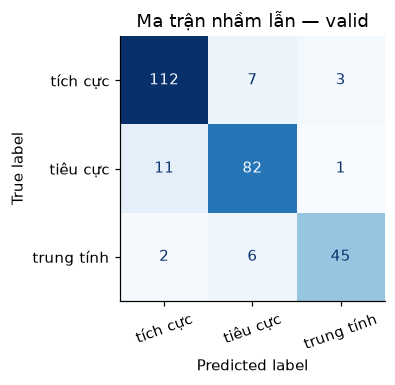

In [5]:
print(classification_report(y_va, pred, digits=3))
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay.from_predictions(y_va, pred, labels=LABELS, ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Ma trận nhầm lẫn — valid"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

Đọc ma trận: hàng là nhãn thật, cột là nhãn đoán. Ngoài đường chéo là các lỗi. Nhãn *trung tính* (lớp hiếm nhất) thường có recall thấp nhất: đó là lớp mô hình dễ bỏ sót.

## 4. Cross-validation: đánh giá ổn định hơn

Một lần chia train/valid cho một con số có thể may hoặc xui. **K-fold** chia train thành K phần, lần lượt giữ một phần làm kiểm tra: ta được K điểm số và có thể báo cáo *trung bình ± độ lệch chuẩn*. Dùng `StratifiedKFold` để mỗi fold giữ tỉ lệ nhãn.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
rows = []
for ten, clf in models.items():
    s = cross_val_score(tao_pipe(clf), X_tr, y_tr, cv=cv, scoring="f1_macro")
    rows.append({"mô hình": ten, "macro-F1 (TB)": s.mean().round(3), "độ lệch chuẩn": s.std().round(3), "các fold": s.round(3).tolist()})
pd.DataFrame(rows)

,mô hình,macro-F1 (TB),độ lệch chuẩn,các fold
0,Naive Bayes,0.804,0.022,"[0.789, 0.775, 0.802, 0.816, 0.84]"
1,Logistic Regression,0.860,0.014,"[0.842, 0.85, 0.878, 0.856, 0.872]"
2,Linear SVM,0.860,0.021,"[0.828, 0.848, 0.879, 0.858, 0.887]"


Nếu hiệu giữa hai mô hình *nhỏ hơn độ lệch chuẩn giữa các fold* thì ta chưa có bằng chứng mô hình nào tốt hơn. Đừng chọn mô hình chỉ vì hơn kém 0,3 điểm trên một lần chạy.

## 5. Chỉnh siêu tham số bằng `GridSearchCV`

Thử lưới các tham số, mỗi tổ hợp được cross-validate **chỉ trên train**. Vì dùng `Pipeline`, TF-IDF được `fit` lại trong mỗi fold. Tập valid không được chạm tới trong lúc chọn tham số.

In [7]:
pipe = tao_pipe(LogisticRegression(max_iter=2000))
grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "clf__C": [0.3, 1, 3, 10, 30],
}
gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=1).fit(X_tr, y_tr)
print("Tham số tốt nhất:", gs.best_params_)
print(f"macro-F1 CV (train): {gs.best_score_:.3f}")

kq = pd.DataFrame(gs.cv_results_)[["param_tfidf__ngram_range", "param_tfidf__min_df", "param_clf__C", "mean_test_score", "std_test_score"]]
kq.sort_values("mean_test_score", ascending=False).head(6).round(3)

Tham số tốt nhất: {'clf__C': 10, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
macro-F1 CV (train): 0.866


,param_tfidf__ngram_range,param_tfidf__min_df,param_clf__C,mean_test_score,std_test_score
12,"(1, 1)",1,10.0,0.866,0.019
14,"(1, 1)",2,10.0,0.863,0.016
10,"(1, 1)",2,3.0,0.862,0.021
8,"(1, 1)",1,3.0,0.861,0.022
16,"(1, 1)",1,30.0,0.861,0.018
18,"(1, 1)",2,30.0,0.861,0.018


## 6. Lớp mất cân bằng

Khi `trung tính` chỉ chiếm ~18%, mô hình có xu hướng ưu tiên lớp lớn. `class_weight="balanced"` tăng "trọng số lỗi" cho lớp hiếm. Kết quả là recall của lớp hiếm thường tăng, đổi lại precision của nó có thể giảm — **một sự đánh đổi, không phải miễn phí**.

In [8]:
rows = []
for cw in [None, "balanced"]:
    m = tao_pipe(LogisticRegression(C=10, max_iter=2000, class_weight=cw)).fit(X_tr, y_tr)
    p_, r_, f_, _ = precision_recall_fscore_support(y_va, m.predict(X_va), labels=LABELS, zero_division=0)
    rows.append({"class_weight": str(cw), **{f"recall {l}": round(x, 3) for l, x in zip(LABELS, r_)},
                 "recall TB (macro)": round(r_.mean(), 3), "macro-F1": round(f_.mean(), 3)})
pd.DataFrame(rows)

,class_weight,recall tích cực,recall tiêu cực,recall trung tính,recall TB (macro),macro-F1
0,None,0.918,0.872,0.849,0.880,0.886
1,balanced,0.902,0.872,0.868,0.881,0.879


## 7. Mở hộp: mô hình dựa vào đâu để quyết định?

Với Logistic Regression ta đọc được hệ số theo từng lớp. Nếu các đặc trưng hàng đầu vô lý (ví dụ chỉ là tên một người dùng hay một dấu câu), đó là dấu hiệu mô hình đang học lối tắt.

In [9]:
lr = tao_pipe(LogisticRegression(C=10, max_iter=2000)).fit(X_tr, y_tr)
ten_dt = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coef = lr.named_steps["clf"].coef_
for i, lab in enumerate(lr.named_steps["clf"].classes_):
    top = ten_dt[coef[i].argsort()[::-1][:10]]
    print(f"{lab:11s}: " + " | ".join(top))

tiêu cực   : hơi | chậm | thiếu | lâu | chưa | cham | sẽ không | quay lại | không quay | chật
trung tính : điểm | ưu | nhược | nhược điểm | ưu điểm | tạm | bình | được | cũng | cũng được
tích cực   : hề | đáng | chẳng hề | recommend | dễ | mượt | ngắn | nhé | recommend nhé | không hề


Hầu hết đặc trưng hợp lý ("chậm", "thiếu", "mượt", "đáng"). Nhưng lớp *trung tính* dựa vào "ưu điểm", "nhược điểm" — một **lối tắt** của dữ liệu tổng hợp này, vì mẫu "Ưu điểm: …. Nhược điểm: …." luôn mang nhãn trung tính. Trên bình luận thật đó không phải quy luật; việc đọc hệ số giúp ta phát hiện được điều này.

## 8. Phân tích lỗi: nơi học được nhiều nhất

Điểm số chỉ cho biết *bao nhiêu* lỗi; phân tích lỗi cho biết *vì sao*. Ta gắn thẻ các đặc điểm ngôn ngữ vào từng câu rồi so sánh tỉ lệ lỗi giữa các nhóm.

In [10]:
valid_pred = lr.predict(X_va)
ev = valid.assign(du_doan=valid_pred, sai=(valid_pred != y_va.values))

NEG_W = ("không", "chưa", "chẳng")
ev["co_phu_dinh"] = ev["clean"].map(lambda t: any(f" {w} " in f" {t} " for w in NEG_W))
ev["co_nhung"] = ev["clean"].str.contains(r"\bnhưng\b")
ev["khong_dau"] = ev["text"].map(lambda t: strip_accents(t) == t and any(c.isalpha() for c in t))
ev["co_emoji"] = ev["text"].str.contains(r"[^\w\s.,!?:;\-\"'()%/…]")

bang = {ten: (ev[ev[ten]]["sai"].mean(), ev[ten].sum()) for ten in ["co_phu_dinh", "co_nhung", "khong_dau", "co_emoji"]}
bang["tất cả"] = (ev["sai"].mean(), len(ev))
pd.DataFrame(bang, index=["tỉ lệ lỗi", "số câu"]).T.round(3)

,tỉ lệ lỗi,số câu
co_phu_dinh,0.081,62.0
co_nhung,0.162,37.0
khong_dau,0.227,22.0
co_emoji,0.054,37.0
tất cả,0.112,269.0


Con số đáng chú ý: câu **không dấu** (~23%) và câu có **"nhưng"** (~16%) bị sai nhiều hơn mức trung bình (~11%). Ngược lại, câu có phủ định lại sai *ít* hơn trung bình vì dữ liệu huấn luyện có nhiều khuôn "không + tính từ" và bigram bắt được chúng — nhưng đến mục 9 ta sẽ thấy điều này không còn đúng với câu mới.

In [11]:
print("Một số câu bị đoán sai:\n")
for _, r_ in ev[ev["sai"]].sample(min(10, ev["sai"].sum()), random_state=1).iterrows():
    print(f"[thật: {r_['label']:10s} | đoán: {r_['du_doan']:10s}] {r_['text']}")

Một số câu bị đoán sai:

[thật: tích cực   | đoán: tiêu cực  ] Giao diện đẹp.
[thật: trung tính | đoán: tích cực  ] Tuy tài liệu cực kỳ dễ theo dõi nhưng học phí hơi cao.
[thật: tiêu cực   | đoán: tích cực  ] Mới nhận hàng nên chưa đánh giá được nhiều. Giá khá cao.
[thật: tiêu cực   | đoán: tích cực  ] Mình đến vào giờ cao điểm. Nhân viên hướng dẫn theo đúng quy trình. Nhân viên khá thờ ơ.
[thật: trung tính | đoán: tiêu cực  ] Lớp có khoảng ba mươi học viên.
[thật: tiêu cực   | đoán: tích cực  ] Mình dùng được một tuần rồi. Giao hàng rất chậm, lại còn giá cao.
[thật: tiêu cực   | đoán: tích cực  ] Minh dung dich vu lan thu hai. Thoi gian cho qua dai, nhan vien hoi tho o. Khong khuyen mua.
[thật: tiêu cực   | đoán: tích cực  ] Mình học buổi tối sau giờ làm. Bài tập quá ít!!!
[thật: tiêu cực   | đoán: tích cực  ] Cài về từ tháng trước. Tuy thông báo khá kịp thời nhưng ứng dụng hay văng. 👎
[thật: trung tính | đoán: tiêu cực  ] Cài về từ tháng trước. Tính năng thừa thãi, lại còn ứng dụng n

### 8.1 Dùng mô hình để soi *nhãn sai*

Nhãn của con người cũng có lỗi (bộ dữ liệu này cố ý đảo ~3% nhãn). Mẹo "data debugging": lấy dự đoán **ngoài-fold** bằng cross-validation, rồi xem các mẫu mà mô hình **rất chắc** về một nhãn *khác* nhãn được gán. Đó là ứng viên nhãn nhiễu.

In [12]:
oof = cross_val_predict(tao_pipe(LogisticRegression(C=10, max_iter=2000)), X_tr, y_tr, cv=cv, method="predict_proba")
classes = np.array(sorted(LABELS))
pred_oof = classes[oof.argmax(axis=1)]
conf = oof.max(axis=1)
nghi = train.assign(du_doan=pred_oof, do_chac=conf)
nghi = nghi[nghi["du_doan"] != nghi["label"]].sort_values("do_chac", ascending=False)
print(f"{len(nghi)} mẫu có dự đoán ngoài-fold khác nhãn; 10 mẫu mô hình chắc nhất:\n")
for _, r_ in nghi.head(10).iterrows():
    print(f"[gán: {r_['label']:10s} | mô hình: {r_['du_doan']:10s} | {r_['do_chac']:.2f}] {r_['text']}")

173 mẫu có dự đoán ngoài-fold khác nhãn; 10 mẫu mô hình chắc nhất:

[gán: tiêu cực   | mô hình: trung tính | 0.99] Chi phí bình thường. Cho 3 sao.
[gán: trung tính | mô hình: tích cực   | 0.99] giao diện hơi xấu nhưng bù lại hỗ trợ khách hàng rất nhiệt tình. cho 5 sao.
[gán: trung tính | mô hình: tiêu cực   | 0.99] chi phí hơi cao, lại còn nhân viên rất cáu gắt. cho 1 sao.
[gán: trung tính | mô hình: tiêu cực   | 0.98] Thông báo hơi hay trễ và giao diện quá rối.
[gán: trung tính | mô hình: tiêu cực   | 0.98] Giá cao. Cho 1 sao.
[gán: tiêu cực   | mô hình: tích cực   | 0.97] Tốc độ không nhanh.
[gán: tích cực   | mô hình: trung tính | 0.97] Mới nhận hàng nên chưa đánh giá đc nhiều. Chưa biết có dùng lại k.
[gán: tiêu cực   | mô hình: tích cực   | 0.96] Thời gian chờ cực kỳ ngắn, nhưng thủ tục rườm rà.
[gán: trung tính | mô hình: tiêu cực   | 0.96] Thủ tục khá rườm rà. Cho 1 sao.
[gán: trung tính | mô hình: tiêu cực   | 0.95] Dùng trên điện thoại Android dc hai tuần. Hỗ trợ khách hàng qu

Hãy tự đọc và phán đoán: trong danh sách trên, nhãn nào *hợp lý hơn* — nhãn được gán hay nhãn mô hình đoán? Những mẫu mà bạn đồng ý với mô hình (như "Chi phí hơi cao, lại còn nhân viên rất cáu gắt. Cho 1 sao." bị gán *trung tính*) chính là nhãn sai. Những mẫu bạn đồng ý với nhãn (như "Tốc độ không nhanh." bị đoán là *tích cực* với độ chắc 0,97) là **lỗi của mô hình** — cũng là thông tin quý, vì nó cho thấy mô hình chưa hiểu phủ định. Sửa nhãn (hoặc loại bỏ) thường cải thiện chất lượng nhiều hơn là đổi mô hình.

## 9. Tập câu khó: điểm trên `valid` có đáng tin không?

`data/reviews_hard.csv` gồm 40 câu viết tay, mỗi câu thuộc một **hiện tượng ngôn ngữ**: phủ định, đối lập "nhưng", mỉa mai, không dấu, câu hỏi, emoji ngược nghĩa... Mô hình chưa từng thấy các kiểu câu này.

In [13]:
mh = lr
pred_h = mh.predict(hard["clean"])
hard["du_doan"] = pred_h
hard["dung"] = hard["du_doan"] == hard["label"]

print(f"Accuracy trên valid (cùng khuôn câu) : {accuracy_score(y_va, valid_pred):.3f}")
print(f"Accuracy trên câu khó (viết tay)     : {hard['dung'].mean():.3f}   (n = {len(hard)})")
print(f"Macro-F1 trên câu khó                : {f1_score(hard['label'], pred_h, average='macro'):.3f}\n")

bang = hard.groupby("hien_tuong")["dung"].agg(["mean", "count"]).rename(columns={"mean": "tỉ lệ đúng", "count": "số câu"})
bang.sort_values("tỉ lệ đúng").round(2)

Accuracy trên valid (cùng khuôn câu) : 0.888
Accuracy trên câu khó (viết tay)     : 0.575   (n = 40)
Macro-F1 trên câu khó                : 0.563



,tỉ lệ đúng,số câu
hien_tuong,,
câu hỏi,0.00,2
không có từ cảm xúc rõ,0.25,4
phủ định của từ tiêu cực,0.25,4
lưỡng lự,0.33,3
mỉa mai,0.33,3
emoji ngược nghĩa,0.50,2
teencode,0.50,2
đối lập (vế sau quyết định),0.62,8
phủ định,1.00,1


In [14]:
print("Các câu khó bị đoán sai:\n")
for _, r_ in hard[~hard["dung"]].iterrows():
    print(f"[{r_['hien_tuong']}] thật: {r_['label']:10s} | đoán: {r_['du_doan']:10s} | {r_['text']}")

Các câu khó bị đoán sai:

[phủ định của từ tiêu cực] thật: tích cực   | đoán: tiêu cực   | Sản phẩm không tệ chút nào.
[đối lập (vế sau quyết định)] thật: tiêu cực   | đoán: tích cực   | Giá rẻ nhưng chất lượng kém quá.
[đối lập (vế sau quyết định)] thật: tích cực   | đoán: tiêu cực   | Ứng dụng hơi giật lúc đầu nhưng cập nhật xong mượt hẳn.
[mỉa mai] thật: tiêu cực   | đoán: trung tính | Hay thật đấy... mới dùng ba ngày đã hỏng.
[mỉa mai] thật: tiêu cực   | đoán: trung tính | Tuyệt vời ghê luôn. Chờ đúng hai tiếng mới đến lượt.
[teencode] thật: tiêu cực   | đoán: trung tính | sp ko dc nhu mo ta
[câu hỏi] thật: trung tính | đoán: tiêu cực   | Sản phẩm dùng thế nào vậy shop?
[câu hỏi] thật: trung tính | đoán: tích cực   | Có giao hàng ngoài giờ hành chính không ạ?
[phủ định của từ tiêu cực] thật: tích cực   | đoán: trung tính | Không có gì để chê.
[lưỡng lự] thật: trung tính | đoán: tiêu cực   | Không thể nói là tệ nhưng cũng chẳng xuất sắc.
[phủ định của từ tiêu cực] thật: tích cực   |

Accuracy rơi từ ~0,89 trên `valid` xuống ~0,58 trên câu khó. Khoảng cách này là bài học quan trọng nhất của buổi này: **điểm trên tập kiểm tra cùng phân phối với tập huấn luyện chỉ nói về mô hình trong "vùng quen thuộc"**. Khi dữ liệu triển khai khác phân phối (từ mới, kiểu viết mới, mỉa mai...), chất lượng có thể thấp hơn nhiều. Vì vậy ta cần: tập kiểm tra *đại diện cho dữ liệu thật*, và các bài kiểm tra theo hiện tượng như trên (đây là ý tưởng của CheckList).

Lưu ý: 40 câu là *rất ít*; tỉ lệ theo từng hiện tượng (3–6 câu) chỉ mang tính gợi ý, không phải kết luận thống kê.

## 10. Khoảng tin cậy bằng bootstrap

Với 269 mẫu valid, macro-F1 "0,89" có chắc chắn là 0,89 không? **Bootstrap**: lấy mẫu có hoàn lại từ tập kiểm tra nhiều lần, tính lại độ đo mỗi lần, rồi lấy khoảng phân vị 2,5%–97,5%.

In [15]:
rng = np.random.default_rng(0)
y_true = y_va.values
n = len(y_true)
diem = []
for _ in range(1000):
    i = rng.integers(0, n, n)
    diem.append(f1_score(y_true[i], valid_pred[i], average="macro"))
lo, hi = np.percentile(diem, [2.5, 97.5])
print(f"macro-F1 valid = {f1_score(y_true, valid_pred, average='macro'):.3f}, khoảng tin cậy 95% ≈ [{lo:.3f}, {hi:.3f}]")

macro-F1 valid = 0.886, khoảng tin cậy 95% ≈ [0.847, 0.923]


Khi báo cáo, hãy viết cả khoảng tin cậy. Hai mô hình có khoảng tin cậy **chồng lấn nhiều** thì chưa thể kết luận mô hình nào hơn.

## 11. Tiền xử lý thật sự ảnh hưởng bao nhiêu?

Ở Bài 1 ta khẳng định "giữ dấu", "không xóa từ phủ định". Giờ kiểm chứng bằng số, dùng 5-fold CV trên train. Mỗi biến thể chỉ khác nhau ở hàm `preprocessor` của TF-IDF.

In [16]:
import re

PHU_DINH = r"\b(không|chưa|chẳng|hề)\b"
TU_DUNG = r"\b(và|là|của|có|cho|với|không|chưa|chẳng|rất|quá|khá|hơi|nhưng|thì|mà|nên|cũng|được|này|đã|đang|sẽ)\b"

bien_the = {
    "chỉ hạ chữ thường":                  lambda t: t.lower(),
    "normalize (mặc định của khóa học)":  lambda t: normalize(t),
    "normalize + bỏ dấu":                 lambda t: strip_accents(normalize(t)),
    "normalize + xóa từ phủ định":        lambda t: re.sub(PHU_DINH, " ", normalize(t)),
    "normalize + xóa từ dừng (gồm phủ định)": lambda t: re.sub(TU_DUNG, " ", normalize(t)),
}
rows = []
for ten, fn in bien_the.items():
    p = Pipeline([("tfidf", TfidfVectorizer(preprocessor=fn, ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                                            token_pattern=r"(?u)\b\w+\b")),
                  ("clf", LogisticRegression(C=10, max_iter=2000))])
    s = cross_val_score(p, train["text"], y_tr, cv=cv, scoring="f1_macro")
    p.fit(train["text"], y_tr)
    h = f1_score(hard["label"], p.predict(hard["text"]), average="macro")
    rows.append({"biến thể": ten, "CV macro-F1": f"{s.mean():.3f} ± {s.std():.3f}", "macro-F1 câu khó": round(h, 3)})
pd.DataFrame(rows)

,biến thể,CV macro-F1,macro-F1 câu khó
0,chỉ hạ chữ thường,0.862 ± 0.012,0.563
1,normalize (mặc định của khóa học),0.860 ± 0.014,0.563
2,normalize + bỏ dấu,0.881 ± 0.024,0.642
3,normalize + xóa từ phủ định,0.835 ± 0.015,0.468
4,normalize + xóa từ dừng (gồm phủ định),0.847 ± 0.017,0.537


Đọc bảng với hai câu hỏi: (1) chênh lệch có lớn hơn độ lệch chuẩn không? (2) xu hướng trên *câu khó* có cùng chiều với CV không?

- **Xóa từ phủ định làm giảm rõ rệt** cả CV (≈0,835) lẫn câu khó (≈0,47): đúng như Bài 1 đã dự đoán. Xóa cả từ dừng cũng giảm.
- **"Chỉ hạ chữ thường" ≈ "normalize"**: dữ liệu này có ít URL/số điện thoại, nên các bước chuẩn hóa tốn công lại không đổi điểm. Không phải bước nào cũng đáng làm trên mọi tập dữ liệu.
- **Bỏ dấu lại *tăng* điểm** (≈0,88; câu khó ≈0,64), ngược với lời khuyên "giữ dấu" ở Bài 1. Lý do nằm ở dữ liệu: ~6% dòng vốn đã không dấu, nên bỏ dấu *gộp* biến thể có dấu và không dấu về cùng một đặc trưng; đồng thời từ vựng nhỏ nên ít bị nhập nhằng. Với văn bản đa dạng và mô hình tiền huấn luyện (PhoBERT được huấn luyện trên chữ có dấu), kết luận có thể ngược lại.

Bài học: **đừng tin lời khuyên chung chung, kể cả của chính giáo trình này — hãy đo trên dữ liệu của bạn.** Một cách tốt hơn cả hai là *tăng cường dữ liệu*: giữ dấu và thêm bản sao không dấu của các mẫu huấn luyện.

## 12. Chốt mô hình và mở tập test đúng một lần

Quy trình: chọn mô hình + siêu tham số bằng CV/valid → huấn luyện lại trên **train + valid** → báo cáo trên **test một lần duy nhất**.

In [17]:
final = tao_pipe(LogisticRegression(C=gs.best_params_["clf__C"], max_iter=2000),
                 ngram=gs.best_params_["tfidf__ngram_range"], min_df=gs.best_params_["tfidf__min_df"])
trva = pd.concat([train, valid])
final.fit(trva["clean"], trva["label"])
pred_te = final.predict(test["clean"])
print("KẾT QUẢ TRÊN TEST (chỉ báo cáo một lần):")
print(classification_report(test["label"], pred_te, digits=3))
print("Trên câu khó, mô hình cuối:", round(f1_score(hard["label"], final.predict(hard["clean"]), average="macro"), 3), "macro-F1")
print("(mô hình ở mục 9, dùng bigram, đạt:", round(f1_score(hard["label"], lr.predict(hard["clean"]), average="macro"), 3), ")")

KẾT QUẢ TRÊN TEST (chỉ báo cáo một lần):
              precision    recall  f1-score   support

    tiêu cực      0.941     0.870     0.904        92
  trung tính      0.860     0.925     0.892        40
    tích cực      0.915     0.942     0.928       137

    accuracy                          0.914       269
   macro avg      0.906     0.912     0.908       269
weighted avg      0.916     0.914     0.914       269

Trên câu khó, mô hình cuối: 0.478 macro-F1
(mô hình ở mục 9, dùng bigram, đạt: 0.563 )


**Một chi tiết đáng suy nghĩ.** `GridSearchCV` chọn mô hình *unigram* (vì CV nhỉnh hơn), nhưng trên câu khó mô hình này kém hơn bản bigram ở mục 9. Hai kết quả không mâu thuẫn: CV đo *trong* phân phối quen thuộc, còn câu khó đo *ngoài* phân phối, và bigram giúp bắt cụm "không + từ". Với 40 câu, chênh lệch cỡ này chưa đủ ý nghĩa thống kê. Nhưng chú ý: **nếu giờ ta đổi sang bigram vì thấy câu khó tốt hơn, tập câu khó đã trở thành tập validation thứ hai** và không còn là phép thử độc lập. Muốn vậy, hãy viết thêm một tập câu khó mới.

## 13. Tổng kết

- Luôn có baseline (ngốc và luật tay).
- `Pipeline` + cross-validation → không rò rỉ, điểm ổn định hơn, có độ lệch chuẩn.
- Lớp lệch → macro-F1 và recall theo lớp, không chỉ accuracy. `class_weight` là một đánh đổi.
- Phân tích lỗi (theo hiện tượng ngôn ngữ) và phát hiện nhãn nhiễu thường đáng giá hơn đổi mô hình.
- Điểm trên tập cùng phân phối ≠ chất lượng ngoài đời; hãy có tập kiểm tra khó và có khoảng tin cậy.
- Mở test **một lần**.

## Bài tập

1. **(Dễ)** Thêm `SGDClassifier(loss="log_loss")` và `ComplementNB` vào bảng so sánh. Kết quả có ổn định qua các fold không?
2. **(Dễ)** Vẽ biểu đồ precision–recall theo từng lớp từ `classification_report` (dùng `output_dict=True`).
3. **(Vừa)** Cải thiện `luat_tay` để xử lý "không + từ khen" và "A nhưng B" (chỉ tính vế sau "nhưng"). Nó vượt được mô hình học máy trên câu khó không? Thế nào là một so sánh công bằng?
4. **(Vừa)** Chạy lại mục 11 với 3 random_state khác của `StratifiedKFold`. Biến thể nào thay đổi thứ hạng?
5. **(Khó)** Sửa tay 10 nhãn nghi sai ở mục 8.1 (trong một bản sao dữ liệu), huấn luyện lại. Macro-F1 trên `valid` (giữ nguyên) và trên câu khó thay đổi thế nào? Vì sao không nên sửa nhãn của tập `test`?

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. `ComplementNB` thường tốt hơn `MultinomialNB` khi lớp lệch. Báo cáo cả độ lệch chuẩn qua fold.
2. `rep = classification_report(..., output_dict=True)`; lấy `rep[lab]["precision"]`, `rep[lab]["recall"]`.
3. Tách câu theo "nhưng" và chỉ chấm vế cuối; đảo dấu khi sau "không/chưa/chẳng" là từ khen/chê. So sánh công bằng nghĩa là luật cũng chỉ được "học" (chỉnh từ khóa) trên train/valid, không nhìn câu khó.
4. Thay đổi `random_state` của `StratifiedKFold`; nếu thứ hạng đảo qua lại thì chênh lệch không có ý nghĩa thống kê.
5. Sửa nhãn train thường giúp; sửa nhãn test là "gian lận" vì đo lường trên thang đo bạn tự điều chỉnh sau khi đã xem mô hình.
</details>

**Tiếp theo → Bài 4:** mô hình ngôn ngữ n-gram — dự đoán từ kế tiếp.

**Đọc thêm:** [scikit-learn: Model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html) · [CheckList (Ribeiro và cộng sự, ACL 2020)](https://aclanthology.org/2020.acl-main.442/)